# code_194 · The independent unit determines the uncertainty

**Book:** section 36.7. Restart and run all cells. Imports, helpers and generated observations are internal; ordinary execution is offline and CPU-only, with no credentials or files. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_36_GUIDE.md), [execution evidence](../CHAPTER_36_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_194).

Reference runtime: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0 and scikit-learn 1.9.0. Allow two minutes to execute and 45–90 minutes to interpret. Evaluation contracts identify the population, sampling unit, available information, score direction and decision consequences. Original experiments expose metric behaviour; they are not benchmark reproductions or evidence that the generated law describes inspected structures. Simulator-only truth is labelled separately from observable assessment. No final score chooses a model or threshold. No dependency or asset is added.


In [1]:
import platform,time,json,copy
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn,threadpoolctl
from scipy.special import expit
from IPython.display import display
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=7794;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print(platform.system(),platform.machine(),'CPU; seed',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':10,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
Darwin arm64 CPU; seed 7794


<a id="paired-building-resampling"></a>
 ## Resample independent buildings while preserving paired predictions
 Generate 160 source and 60 independent final buildings, each with 20 load records and an unobserved shared disturbance. Fit a source-only linear Ridge and a 64-tree depth-six random forest, using the first of eight predeclared seeds for the primary comparison. All seeds use the same source and final buildings; their final scores are reported as training-seed variation and never select a seed. Compute per-record squared loss difference forest minus ridge, then average within each building. Lower difference favours forest. Bootstrap 900 sets of 60 whole buildings, keeping both models paired; compare with a deliberately inappropriate row bootstrap of 1,200 records. Both target the same equal-size design's average, but only the grouped bootstrap preserves dependence. Intervals condition on fitted predictors and exclude source-sample refitting variation.


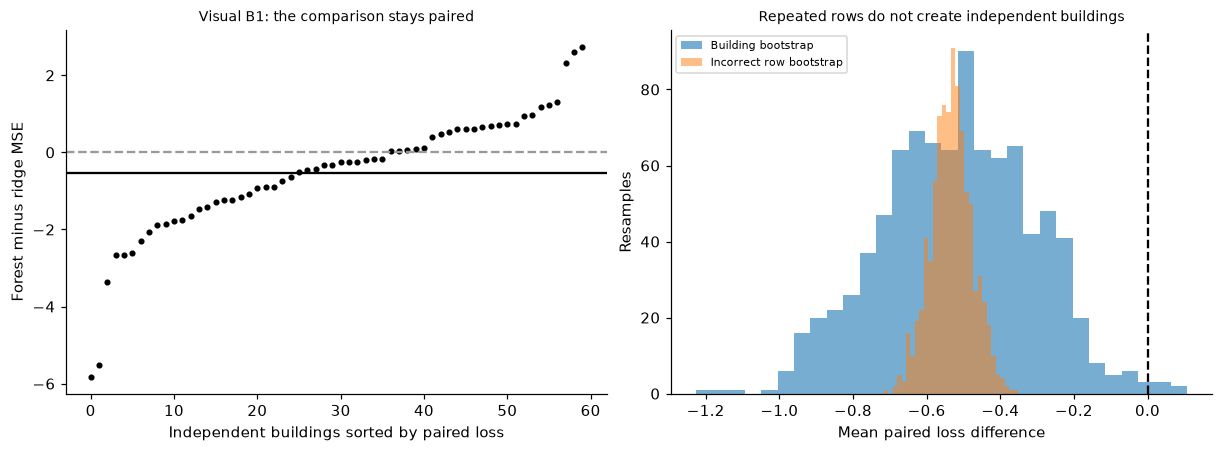

In [2]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
def buildings(n):
    g=np.repeat(np.arange(n),20);z=rng.normal(size=n);load=rng.uniform(0,2,n*20);x=np.c_[z[g],load];y=1.4*np.sin(1.5*z[g])+.6*load*z[g]+rng.normal(scale=.9,size=n)[g]+rng.normal(scale=.2,size=n*20);return x,y,g
xs,ys,gs=buildings(160);xf,yf,gf=buildings(60);ridge=Ridge(alpha=1).fit(xs,ys);pa=ridge.predict(xf);seeds=list(range(SEED,SEED+8));predictions=[RandomForestRegressor(n_estimators=64,max_depth=6,min_samples_leaf=8,n_jobs=1,random_state=s).fit(xs,ys).predict(xf) for s in seeds];pb=predictions[0];loss_a=(pa-yf)**2;loss_b=(pb-yf)**2;delta=(loss_b-loss_a).reshape(60,20);per_building=delta.mean(1);draw=rng.integers(0,60,(900,60));group_boot=per_building[draw].mean(1);row_boot=delta.ravel()[rng.integers(0,1200,(900,1200))].mean(1);ci_group=np.quantile(group_boot,[.025,.975]);ci_row=np.quantile(row_boot,[.025,.975]);seed_mse=[float(np.mean((p-yf)**2)) for p in predictions]
assert delta.shape==(60,20);assert np.isclose(delta.mean(),per_building.mean());assert all(np.isfinite(seed_mse));RESULTS.update(source_buildings=160,assessment_buildings=60,records_per_building=20,primary_seed=seeds[0],seed_list=seeds,forest_MSE_by_seed=seed_mse,primary_ridge_MSE=float(loss_a.mean()),primary_forest_MSE=float(loss_b.mean()),paired_MSE_difference=float(per_building.mean()),building_bootstrap_CI=ci_group.tolist(),incorrect_row_bootstrap_CI=ci_row.tolist(),building_paired_differences=per_building.tolist(),bootstrap_replicates=900,interval_conditions_on_fitted_models=True)
fig,axes=plt.subplots(1,2,figsize=(11,4));ordered=np.argsort(per_building);axes[0].plot(range(60),per_building[ordered],'o',markersize=3,color='black');axes[0].axhline(0,linestyle='--',color='.6');axes[0].axhline(per_building.mean(),color='black');axes[0].set(xlabel='Independent buildings sorted by paired loss',ylabel='Forest minus ridge MSE',title='Visual B1: the comparison stays paired');axes[1].hist(group_boot,bins=30,alpha=.6,label='Building bootstrap');axes[1].hist(row_boot,bins=30,alpha=.5,label='Incorrect row bootstrap');axes[1].axvline(0,color='black',linestyle='--');axes[1].set(xlabel='Mean paired loss difference',ylabel='Resamples',title='Repeated rows do not create independent buildings');axes[1].legend(fontsize=7);plt.show()


<a id="load-slices-and-seed-variation"></a>
 ## Keep subgroup denominators and uncertainty targets visible
 Predeclare three load regimes, below 2/3, between 2/3 and 4/3, and above 4/3. For each building and slice, average each predictor's squared loss; all sampled buildings have at least one record in each slice in this declared run. Average buildings equally and bootstrap the same 60-building draws for pointwise paired-difference intervals. These three intervals are exploratory pointwise intervals, not simultaneous family-wise guarantees. Display actual row and building counts and avoid choosing a final-model revision from them. Separately display eight forest training-seed scores; eight predictions on one cohort do not constitute eight independent datasets or a confidence interval for new-building generalization. Multiple tuning attempts and comparison budgets belong in a report even when only one result is headlined.


,load_slice,records,buildings,ridge_MSE,forest_MSE,paired_MSE_difference,pointwise_building_CI
0,0,394,60,1.300099,0.930090,-0.370009,"[-0.9166859904515015, 0.08561862033956955]"
1,1,379,60,1.447913,1.067695,-0.380219,"[-0.7573924404167472, -0.014587422810675361]"
2,2,427,60,1.932645,1.134628,-0.798017,"[-1.3009871227445364, -0.2769838979306603]"


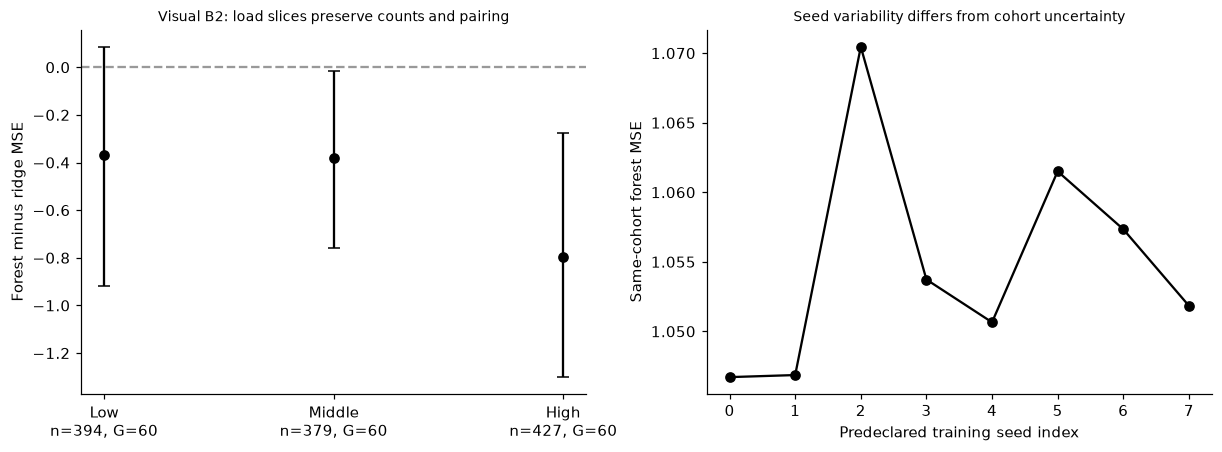

In [3]:
bins=np.digitize(xf[:,1],[2/3,4/3]);slices=[]
for b in range(3):
    mask=bins==b;ids=np.unique(gf[mask]);da=np.array([loss_a[mask&(gf==g)].mean() for g in ids]);db=np.array([loss_b[mask&(gf==g)].mean() for g in ids]);assert len(ids)==60;difference=db-da;boot=difference[draw].mean(1);slices.append({'load_slice':b,'records':int(mask.sum()),'buildings':len(ids),'ridge_MSE':float(da.mean()),'forest_MSE':float(db.mean()),'paired_MSE_difference':float(difference.mean()),'pointwise_building_CI':np.quantile(boot,[.025,.975]).tolist()})
assert sum(v['records'] for v in slices)==1200;RESULTS.update(load_slices=slices,pointwise_intervals_not_simultaneous=True,seed_comparisons_never_choose_model=True);display(pd.DataFrame(slices));fig,axes=plt.subplots(1,2,figsize=(11,4));xx=np.arange(3);means=np.array([v['paired_MSE_difference'] for v in slices]);interval=np.array([v['pointwise_building_CI'] for v in slices]);axes[0].errorbar(xx,means,yerr=np.array([means-interval[:,0],interval[:,1]-means]),fmt='o',color='black',capsize=4);axes[0].axhline(0,color='.6',linestyle='--');axes[0].set(xticks=xx,xticklabels=[f'{label}\nn={v["records"]}, G={v["buildings"]}' for label,v in zip(['Low','Middle','High'],slices)],ylabel='Forest minus ridge MSE',title='Visual B2: load slices preserve counts and pairing');axes[1].plot(range(8),seed_mse,'o-',color='black');axes[1].set(xlabel='Predeclared training seed index',ylabel='Same-cohort forest MSE',title='Seed variability differs from cohort uncertainty');plt.show()


In [4]:
summary={'example_id':'code_194','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual fixed ridge and eight seeded random forest fits', 'paired equal-building loss comparison with building versus row bootstrap', 'source fixed training seed variation separated from cohort uncertainty', 'building-level paired differences and counted load slices Visual B'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual fixed ridge and eight seeded random forest fits", "paired equal-building loss comparison with building versus row bootstrap", "source fixed training seed variation separated from cohort uncertainty", "building-level paired differences and counted load slices Visual B"], "elapsed_seconds": 0.889, "example_id": "code_194", "hardware": "Darwin arm64 CPU", "results": {"assessment_buildings": 60, "bootstrap_replicates": 900, "building_bootstrap_CI": [-0.9242541846188695, -0.1390016927096774], "building_paired_differences": [-0.8865112336355476, -3.355075149910327, 1.183851412334287, -0.7422613515692386, -0.21021559439933696, 0.06569790722845184, -5.830807378097626, -0.31713694718543184, 2.738227037324837, -1.226888112702906, -1.1630951677004489, 0.1073846611308191, -0.17492349977862598, -0.25397770433912836, -1.0788178432824775, -1.244393492002855, 0.7275952172987108, -1.7648390148558515, -2.2894893831253436, -1.2745717808546728, -2.